In [1]:
import logging
logging.captureWarnings(True)

In [2]:
import numpy as np
import networkx as nx

In [3]:
from multifractal_networks.mfng import MultifractalNetworkGenerator
from multifractal_networks.mfnf import MultifractalNetworkFitter
from multifractal_networks.utils.motifs import MotifGenerator

# Load Network

In [4]:
filename = './test_networks/human_proteins_network_figeys.txt'
G = nx.read_edgelist(filename)

In [5]:
len(G)

2239

In [6]:
2 * G.number_of_edges() / G.number_of_nodes()

5.74542206342117

In [7]:
for m_size in [2,3,5,6,7]:
    print(m_size,' k_max: ',int(np.log(len(G))/np.log(m_size))+1)

2  k_max:  12
3  k_max:  8
5  k_max:  5
6  k_max:  5
7  k_max:  4


# Init Fitter

In [8]:
mfnf = MultifractalNetworkFitter(
    G,                                   
    motifs = [
        {'name': 'four_chain', 'matrix': np.array([[0, 1, 0, 0],[1, 0, 1, 0],[0, 1, 0, 1],[0, 0, 1, 0]])},
        {'name': 'three_loop_out', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 1, 0],[1, 1, 0, 0],[1, 0, 0, 0]])},
        {'name': 'four_loop', 'matrix': np.array([[0, 1, 0, 1],[1, 0, 1, 0],[0, 1, 0, 1],[1, 0, 1, 0]])},
        {'name': 'four_semi_clique', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 0, 1],[1, 0, 0, 1],[1, 1, 1, 0]])},
    ],
    sampling_ratios = {
        3: 0.01,
        4: 0.0001
    },
    motif_analyzer_args = {'exact': True, 'bootstrap_iters': None, 'ci': None},
    population_size = 100,
    weights = {
        'rho':9,
        'deg_nn':9,
        'motifs':1,
        'edge':9
    }
)

Measuring graph properties...
Degree distribution...
Degree correlations...
Motifs...
Checking compatibility with 4 user-provided motifs.
Adding custom motif 'four_chain'.
Adding custom motif 'three_loop_out'.
Adding custom motif 'four_loop'.
Adding custom motif 'four_semi_clique'.
Counting motifs of size 3... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:00.767793
Counting motifs of size 4... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:01:02.882143


In [9]:
mfnf.motifs

[{'name': 'edge',
  'matrix': array([[0, 1],
         [1, 0]]),
  'size': 2,
  'count': 6432},
 {'name': 'wedge',
  'matrix': array([[0, 1, 1],
         [1, 0, 0],
         [1, 0, 0]]),
  'size': 3,
  'count': 351088},
 {'name': 'triangle',
  'matrix': array([[0, 1, 1],
         [1, 0, 1],
         [1, 1, 0]]),
  'size': 3,
  'count': 897},
 {'name': 'three_star',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 0, 0],
         [1, 0, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'count': 21162272},
 {'name': 'four_clique',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 1, 1],
         [1, 1, 0, 1],
         [1, 1, 1, 0]]),
  'size': 4,
  'count': 99},
 {'name': 'four_chain',
  'matrix': array([[0, 1, 0, 0],
         [1, 0, 1, 0],
         [0, 1, 0, 1],
         [0, 0, 1, 0]]),
  'size': 4,
  'count': 3567418},
 {'name': 'three_loop_out',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 1, 0],
         [1, 1, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'count': 173524},
 {'name':

# Grid Search

In [10]:
mfnf.find_m_k_P_l(
    m_k_dict = [{'m': 2,  'k': [1,12]},
                {'m': 3,  'k': [1,8]},
                {'m': 5,  'k': [1,5]},
                {'m': 6,  'k': [1,5]},
                {'m': 7,  'k': [1,4]}],
    n_trials = None,
    P_init = 'm x m',
    l_init = 'dirichlet',
    verbose = False,
    grid_search = True,
    optimize_for = 'kl_energy'
)

[I 2025-01-25 14:59:42,490] A new study created in memory with name: no-name-27fa36cf-5aa1-48dd-98ef-c548a5563b75


Grid Search requires 11 trials...


[I 2025-01-25 14:59:57,703] Trial 0 finished with value: 10.110181071072466 and parameters: {'m': 2, 'k': 5}. Best is trial 0 with value: 10.110181071072466.
[I 2025-01-25 15:02:47,524] Trial 1 finished with value: 10.347926155748937 and parameters: {'m': 2, 'k': 10}. Best is trial 0 with value: 10.110181071072466.
[I 2025-01-25 15:03:00,781] Trial 2 finished with value: 11.790456591054621 and parameters: {'m': 2, 'k': 3}. Best is trial 0 with value: 10.110181071072466.
[I 2025-01-25 15:10:08,008] Trial 3 finished with value: 10.32947428861724 and parameters: {'m': 2, 'k': 11}. Best is trial 0 with value: 10.110181071072466.
[I 2025-01-25 15:10:30,665] Trial 4 finished with value: 9.928116995145565 and parameters: {'m': 2, 'k': 7}. Best is trial 4 with value: 9.928116995145565.
[I 2025-01-25 15:10:41,133] Trial 5 finished with value: 12.505095248265507 and parameters: {'m': 2, 'k': 2}. Best is trial 4 with value: 9.928116995145565.
[I 2025-01-25 15:11:13,802] Trial 6 finished with valu

Grid Search requires 7 trials...


[I 2025-01-25 15:32:59,833] Trial 0 finished with value: 8.92148205846897 and parameters: {'m': 3, 'k': 7}. Best is trial 0 with value: 8.92148205846897.
[I 2025-01-25 15:33:33,036] Trial 1 finished with value: 7.571101410555375 and parameters: {'m': 3, 'k': 3}. Best is trial 1 with value: 7.571101410555375.
[I 2025-01-25 15:33:55,503] Trial 2 finished with value: 6.870402268573931 and parameters: {'m': 3, 'k': 2}. Best is trial 2 with value: 6.870402268573931.
[I 2025-01-25 15:34:37,440] Trial 3 finished with value: 7.482769173591457 and parameters: {'m': 3, 'k': 4}. Best is trial 2 with value: 6.870402268573931.
[I 2025-01-25 15:34:55,603] Trial 4 finished with value: 18.48387637785052 and parameters: {'m': 3, 'k': 1}. Best is trial 2 with value: 6.870402268573931.
[I 2025-01-25 15:38:56,413] Trial 5 finished with value: 8.335438709396444 and parameters: {'m': 3, 'k': 6}. Best is trial 2 with value: 6.870402268573931.
[I 2025-01-25 15:40:22,385] Trial 6 finished with value: 8.6026152

Grid Search requires 4 trials...


... (2 outputs left out)

[I 2025-01-25 15:53:07,653] Trial 0 finished with value: 6.266067639820478 and parameters: {'m': 6, 'k': 3}. Best is trial 0 with value: 6.266067639820478.
[I 2025-01-25 16:16:26,653] Trial 1 finished with value: 6.237143204380132 and parameters: {'m': 6, 'k': 4}. Best is trial 1 with value: 6.237143204380132.
[I 2025-01-25 16:17:41,494] Trial 2 finished with value: 5.8528426090350445 and parameters: {'m': 6, 'k': 2}. Best is trial 2 with value: 5.8528426090350445.
[I 2025-01-25 16:18:25,522] Trial 3 finished with value: 6.6153566087655395 and parameters: {'m': 6, 'k': 1}. Best is trial 2 with value: 5.8528426090350445.
[I 2025-01-25 16:18:25,524] A new study created in memory with name: no-name-c0920aec-9e2b-43c5-9620-364552abd40f


Grid Search requires 3 trials...


[I 2025-01-25 16:23:49,114] Trial 0 finished with value: 5.503684762546012 and parameters: {'m': 7, 'k': 3}. Best is trial 0 with value: 5.503684762546012.
[I 2025-01-25 16:25:12,424] Trial 1 finished with value: 6.12099178220985 and parameters: {'m': 7, 'k': 2}. Best is trial 0 with value: 5.503684762546012.
[I 2025-01-25 16:26:01,906] Trial 2 finished with value: 16.144541142654223 and parameters: {'m': 7, 'k': 1}. Best is trial 0 with value: 5.503684762546012.


Best parameters:  {'m': 7, 'k': 3}
Best energy:  10.135036828471401
Best KL-divergence:  0.24708501025166496
Best KLD augumented energy: 5.503684762546012
Best P matrix:
 [[1.83533684e-01 6.12775727e-07 3.90767994e-07 1.94883179e-03
  7.74409274e-01 6.10369733e-02 6.33013910e-02]
 [6.12775727e-07 3.70213047e-03 1.01047756e-08 9.15225978e-01
  9.98744940e-01 8.12148424e-01 8.69136314e-01]
 [3.90767994e-07 1.01047756e-08 3.61563328e-01 1.69297468e-03
  4.19633148e-07 8.47889976e-02 7.21591340e-01]
 [1.94883179e-03 9.15225978e-01 1.69297468e-03 9.37528296e-01
  4.43483069e-03 9.77830242e-01 9.99999440e-01]
 [7.74409274e-01 9.98744940e-01 4.19633148e-07 4.43483069e-03
  7.10792668e-08 1.43416829e-01 9.96653369e-01]
 [6.10369733e-02 8.12148424e-01 8.47889976e-02 9.77830242e-01
  1.43416829e-01 8.38750792e-01 9.84630587e-01]
 [6.33013910e-02 8.69136314e-01 7.21591340e-01 9.99999440e-01
  9.96653369e-01 9.84630587e-01 9.10866139e-01]]
Best l vector:
 [3.90954287e-01 3.84646813e-01 1.15560575e

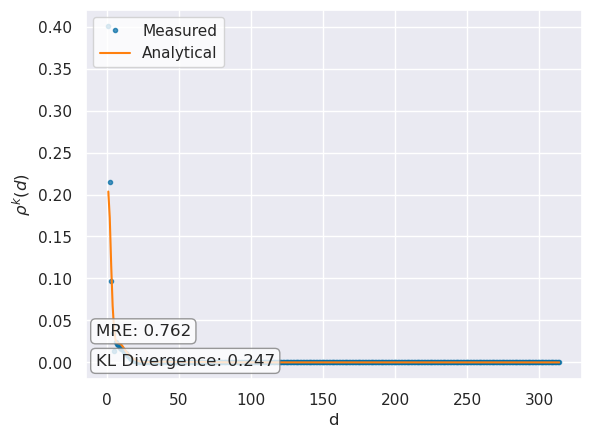

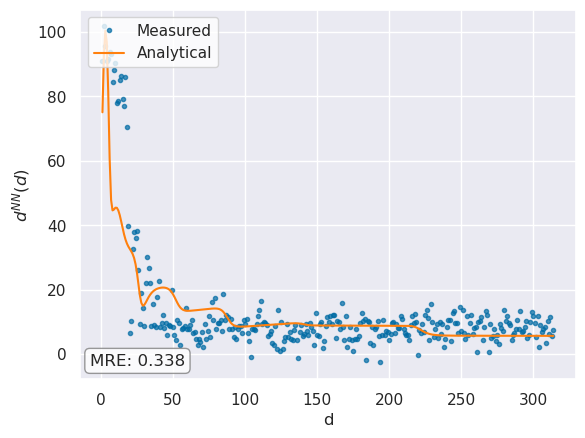

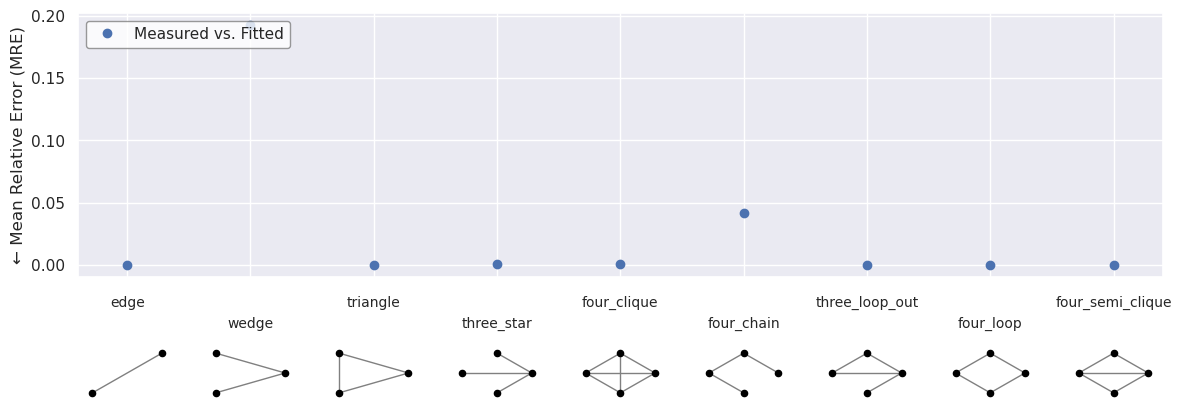

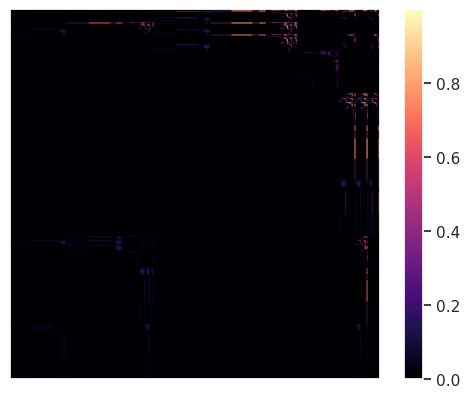

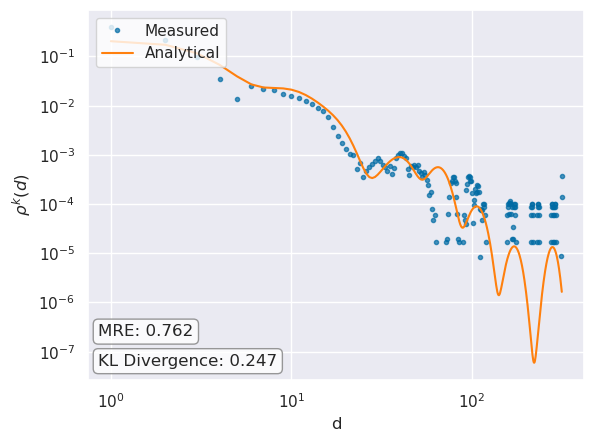

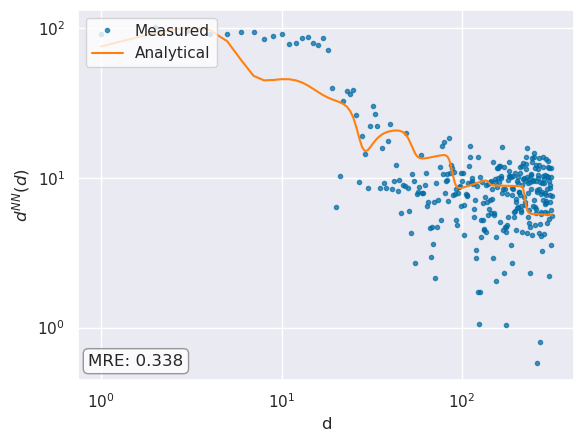

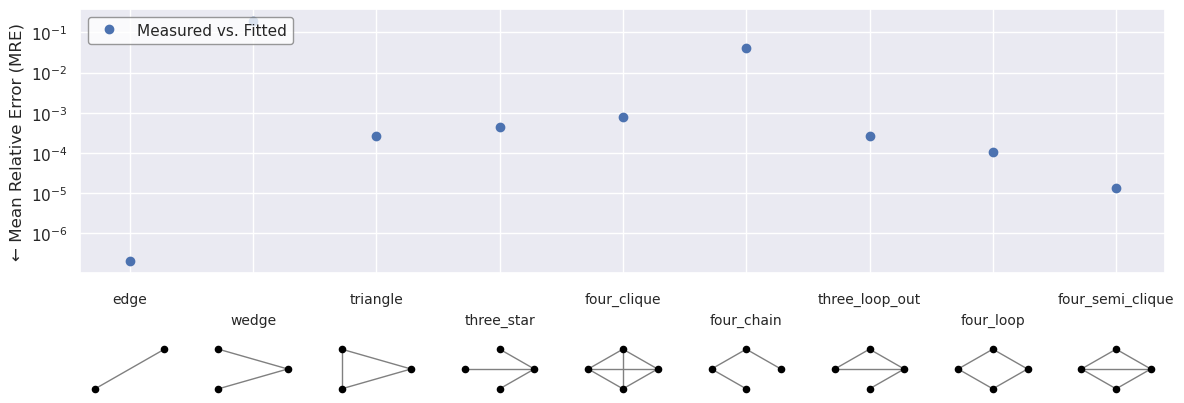

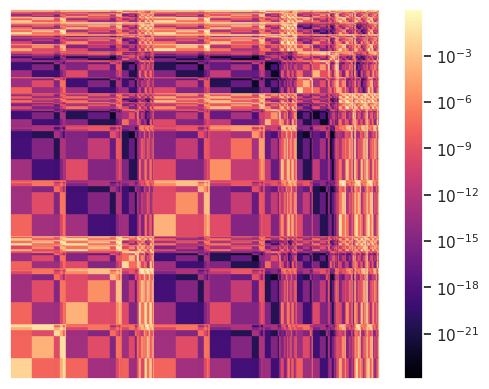

In [11]:
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    #filename = "figures/human_proteins_network_plot.pdf"
)
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    #filename = "figures/human_proteins_network_log_plot.pdf"
)

# Bootstrapping Stability

In [12]:
mfnf.bootstrap_P_l_stability(
    P_init = 'm x m',
    l_init = 'dirichlet',
    verbose = True,
    resample_size = mfnf.population_size,
    ci = 0.95,
    medoid = 'mean'
)

Gathering statistics (30 runs)...


100%|██████████| 30/30 [2:30:37<00:00, 301.24s/it]  

Bootstrapping: Resampling 100 times...


Bootstrapping finished in 0:00:00.486534
Energy = 10.01 (9.94, 10.11)
l = [0.49 (0.30, 0.60), 0.21 (0.12, 0.33), 0.13 (0.05, 0.21), 0.08 (0.03, 0.13), 0.05 (0.03, 0.09), 0.03 (0.00, 0.06), 0.01 (0.00, 0.04)]
P = [
[0.01 (0.00, 0.02), 0.00 (0.00, 0.03), 0.05 (0.00, 0.55), 0.37 (0.00, 1.00), 0.48 (0.00, 1.00), 0.44 (0.00, 1.00), 0.44 (0.00, 0.99)],

[0.00 (0.00, 0.03), 0.16 (0.00, 0.68), 0.19 (0.00, 1.00), 0.29 (0.00, 1.00), 0.38 (0.00, 1.00), 0.44 (0.00, 1.00), 0.32 (0.00, 1.00)],

[0.05 (0.00, 0.55), 0.19 (0.00, 1.00), 0.54 (0.00, 1.00), 0.27 (0.00, 1.00), 0.22 (0.00, 0.98), 0.35 (0.00, 1.00), 0.37 (0.00, 1.00)],

[0.37 (0.00, 1.00), 0.29 (0.00, 1.00), 0.27 (0.00, 1.00), 0.41 (0.00, 1.00), 0.39 (0.00, 1.00), 0.37 (0.00, 1.00), 0.42 (0.00, 1.00)],

[0.48 (0.00, 1.00), 0.38 (0.00, 1.00), 0.22 (0.00, 0.98), 0.39 (0.00, 1.00), 0.43 (0.00, 1.00), 0.49 (0.00, 1.00), 0.56 (0.00, 1.00)],

[0.44 (0.00, 1.00), 0.44 (0.00, 1.00), 0.35 (0.00, 1.00), 0.37 (0.00, 1.00), 0.49 (0.00, 1.00), 0.56 (0.00

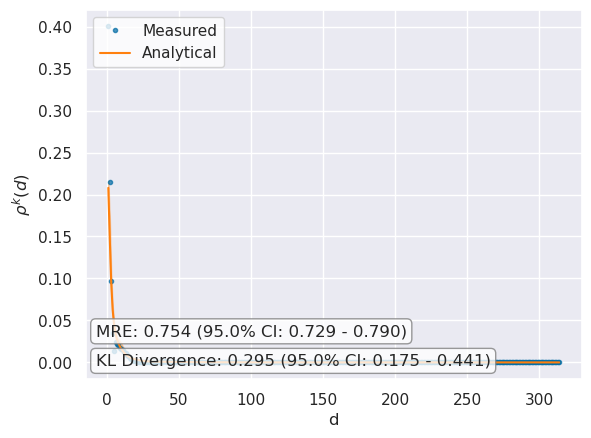

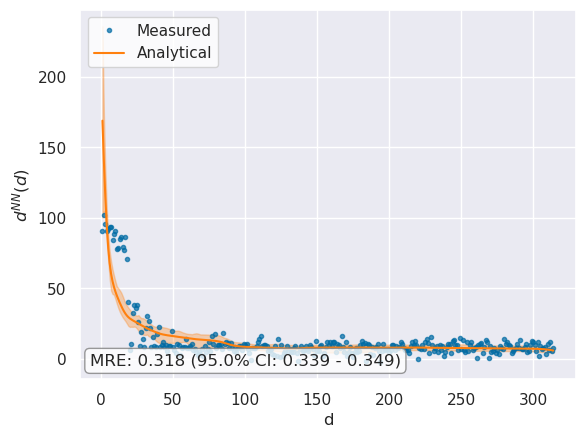

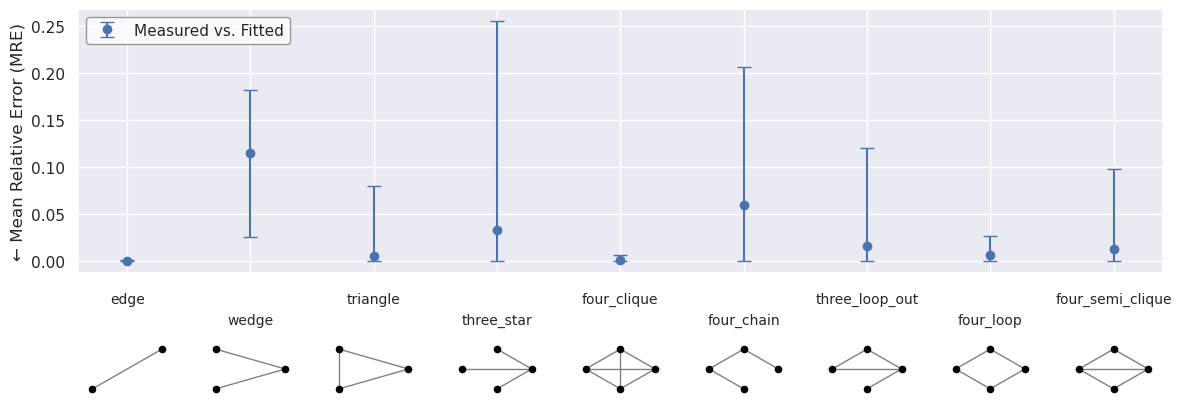

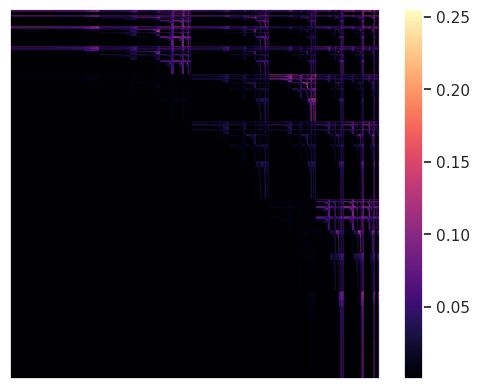

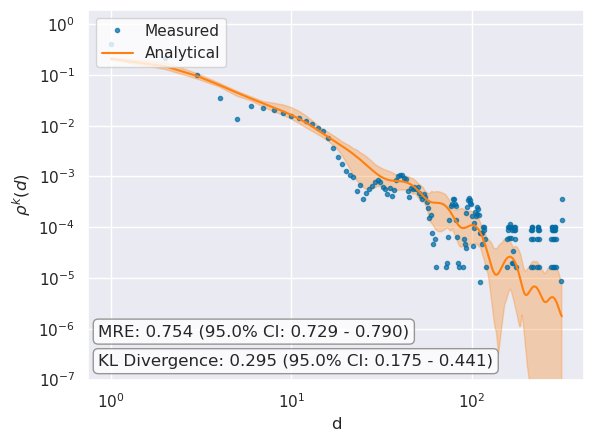

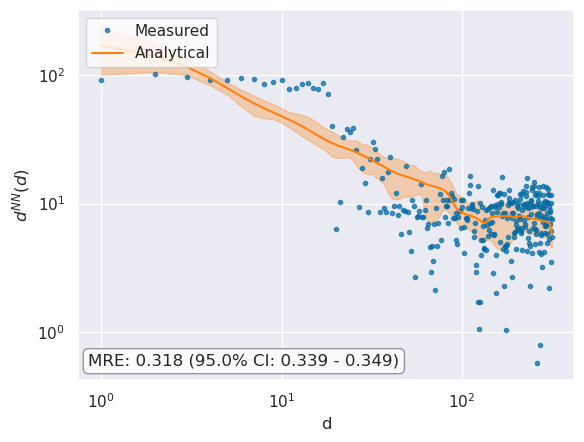

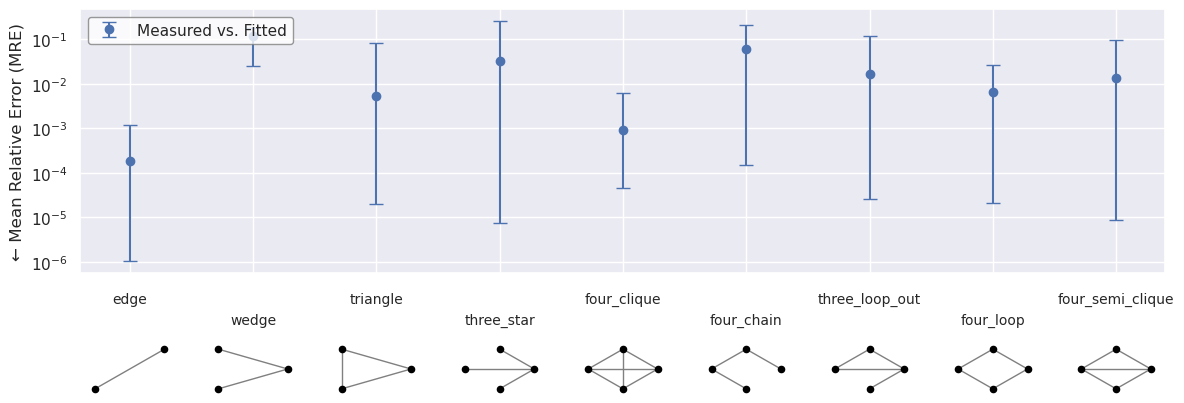

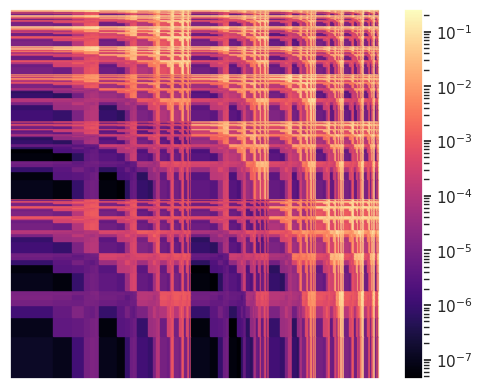

In [16]:
mfnf.plot_P_l_result(
    log_scale = False,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/human_proteins_network_figeys_plot.pdf"
)
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    ylim=[1e-7,0],
    filename = "figures/human_proteins_network_figeys_log_plot.pdf"
)

# Generate Variants

Initializing...
0.0015778541564941406
Calculating betweenness...
Done.
Calculating node positions...
Done.


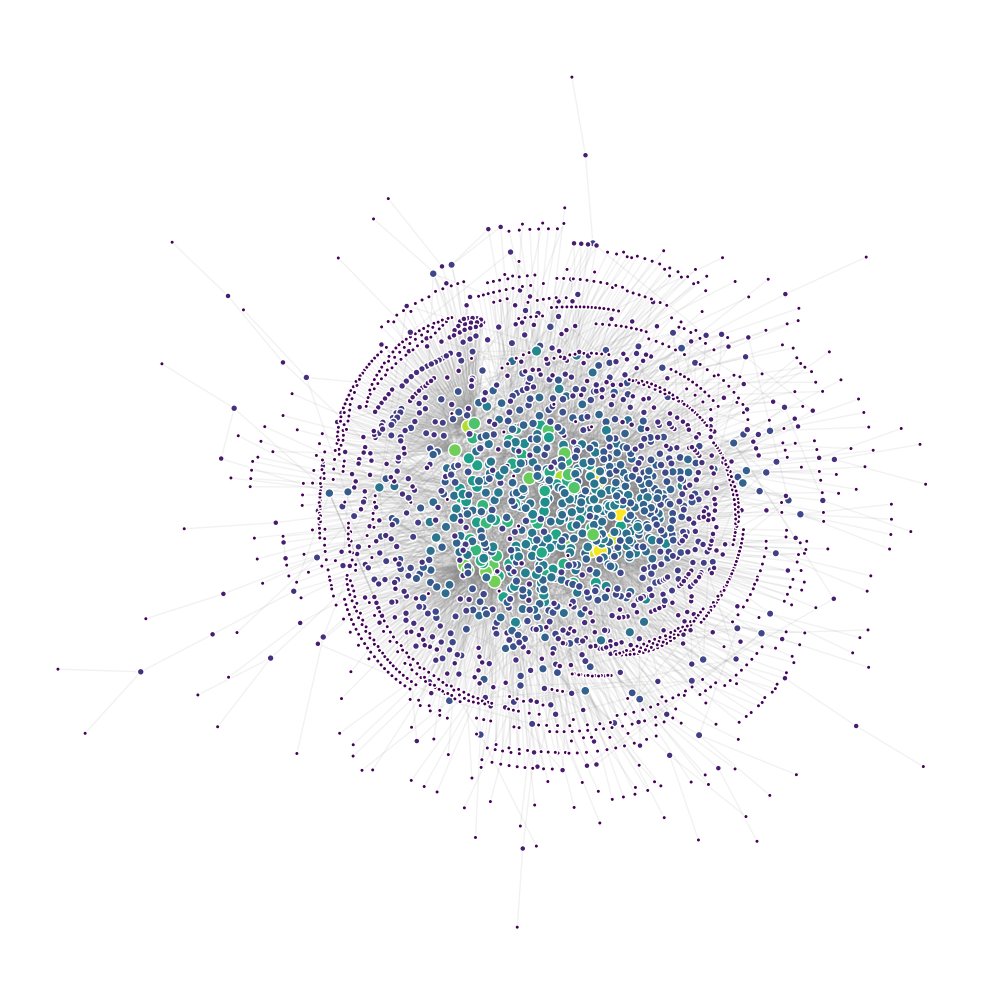

Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:01<00:00, 26.25it/s]


Refining network structure...
Refining 154 outlier nodes...


100%|██████████| 32/32 [00:00<00:00, 57.96it/s]


Refining 22 outlier nodes...


100%|██████████| 32/32 [00:00<00:00, 69.06it/s]


... (7 outputs left out)

100%|██████████| 32/32 [00:00<00:00, 74.39it/s]

Refining 1 outlier nodes...



100%|██████████| 32/32 [00:00<00:00, 72.46it/s]


Calculating betweenness...
Done.
Calculating node positions...
Done.


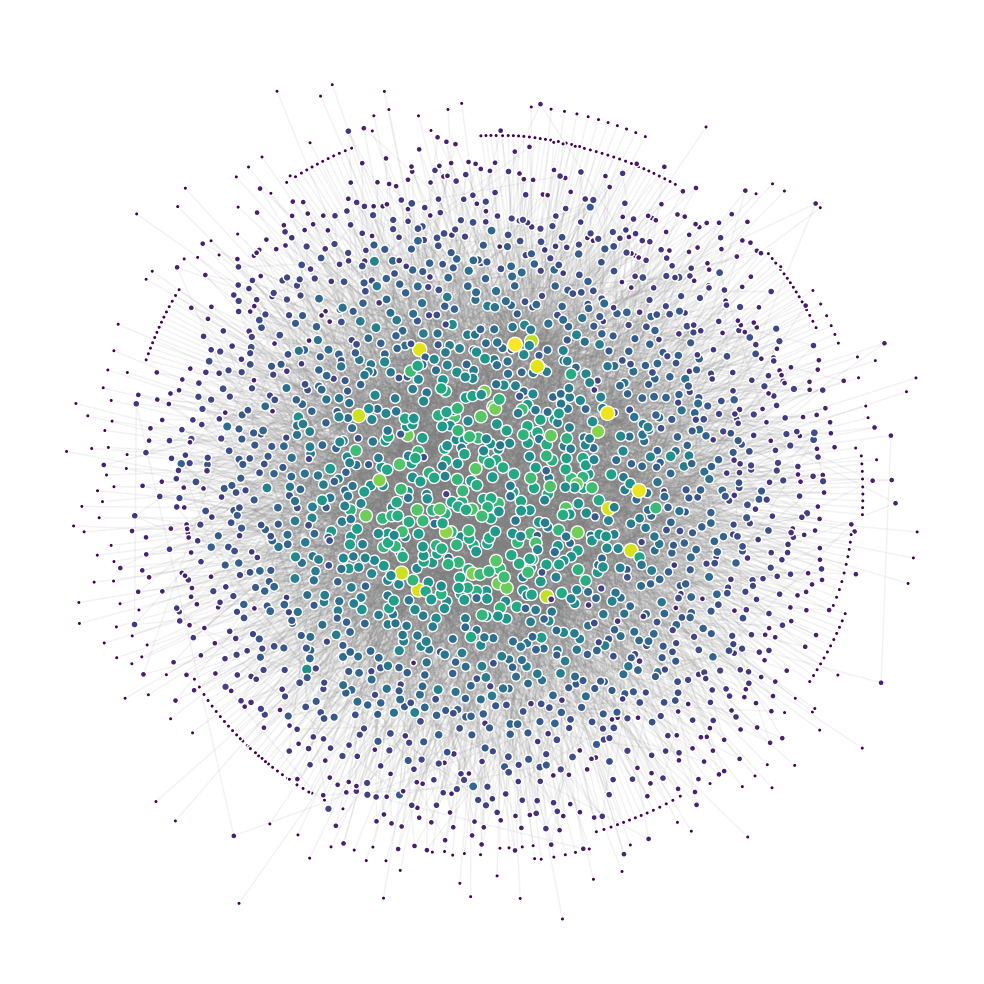

Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:01<00:00, 27.23it/s]


Refining network structure...
Refining 264 outlier nodes...


100%|██████████| 32/32 [00:00<00:00, 59.28it/s]


Refining 75 outlier nodes...


100%|██████████| 32/32 [00:00<00:00, 75.74it/s]


... (7 outputs left out)

100%|██████████| 32/32 [00:00<00:00, 93.92it/s]


Refining 1 outlier nodes...


100%|██████████| 32/32 [00:00<00:00, 94.21it/s]


Calculating betweenness...
Done.
Calculating node positions...
Done.


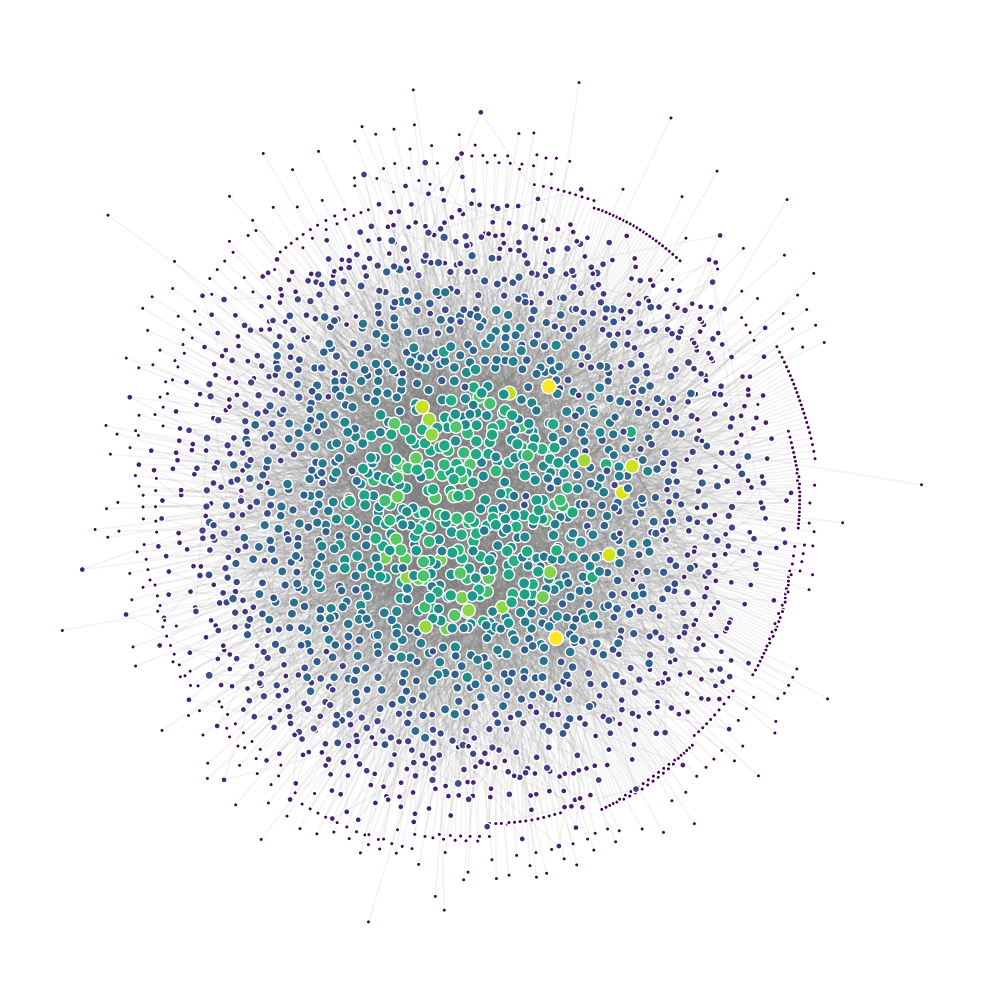

Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:01<00:00, 26.34it/s]


Refining network structure...
Refining 115 outlier nodes...


100%|██████████| 32/32 [00:00<00:00, 65.71it/s]


Refining 18 outlier nodes...


100%|██████████| 32/32 [00:00<00:00, 75.89it/s]

... (11 outputs left out)


100%|██████████| 32/32 [00:00<00:00, 76.46it/s]

Refining 1 outlier nodes...



100%|██████████| 32/32 [00:00<00:00, 77.39it/s]


Calculating betweenness...
Done.
Calculating node positions...
Done.


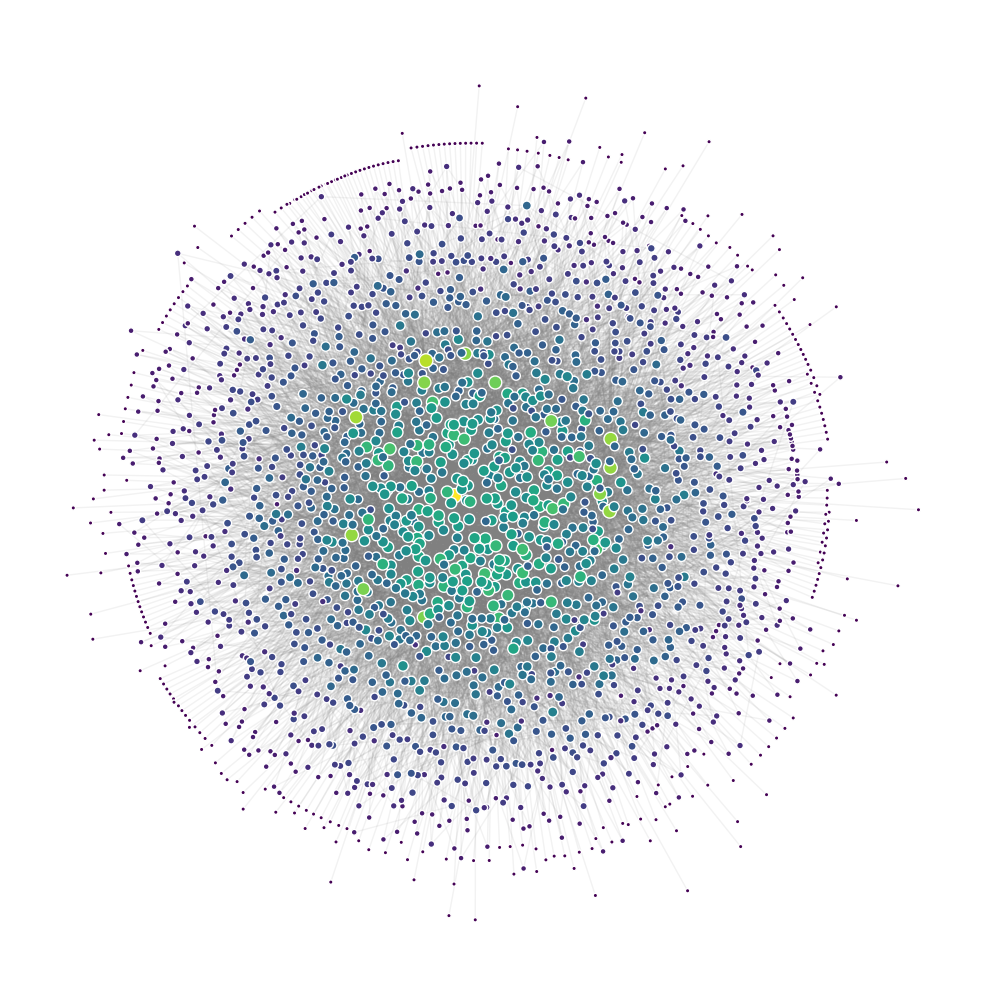

In [17]:
mfnf.generate_variants(
    plot_options = {
        'layout_func': nx.kamada_kawai_layout,
        'figsize': (10,10),
        'filename':  "figures/human_proteins_network_figeys_variants.pdf"
    },
    filename = "variant_networks/human_proteins_network_figeys_variants.graphml"
)

Initializing...
0.0021991729736328125
Calculating betweenness...
Done.
Calculating node positions...
Done.


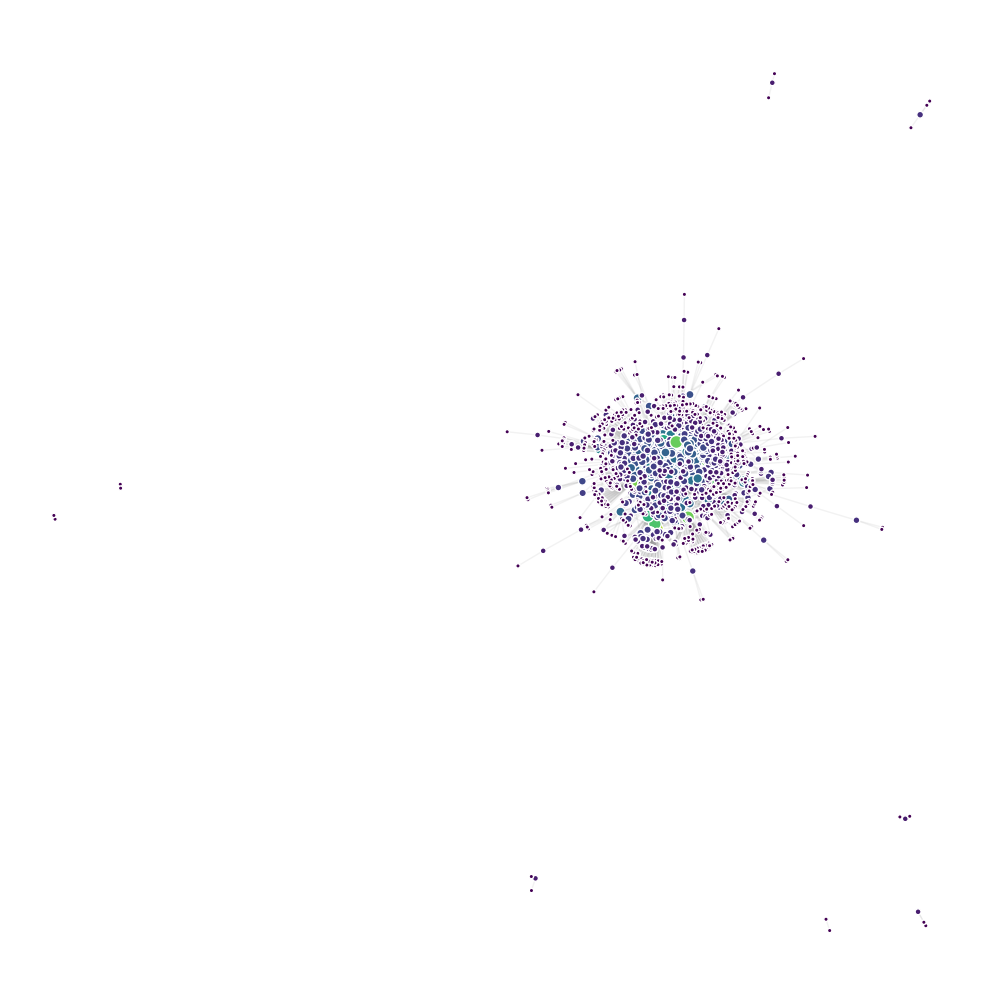

Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:01<00:00, 25.17it/s]


Refining network structure...
Refining 163 outlier nodes...


100%|██████████| 32/32 [00:00<00:00, 53.42it/s]


Refining 36 outlier nodes...


100%|██████████| 32/32 [00:00<00:00, 64.87it/s]


... (5 outputs left out)

100%|██████████| 32/32 [00:00<00:00, 70.79it/s]

Refining 1 outlier nodes...



100%|██████████| 32/32 [00:00<00:00, 70.29it/s]


Calculating betweenness...
Done.
Calculating node positions...
Done.


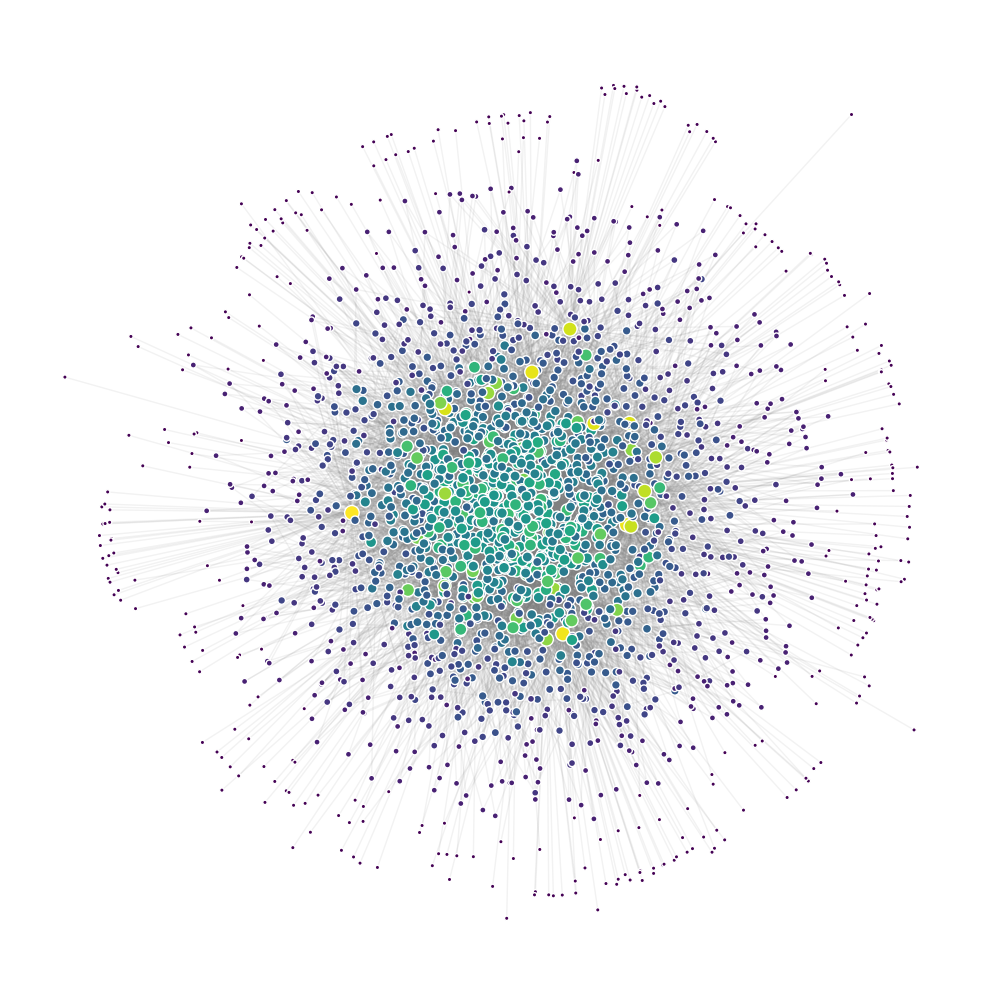

Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:01<00:00, 25.69it/s]


Refining network structure...
Refining 226 outlier nodes...


100%|██████████| 32/32 [00:00<00:00, 59.48it/s]


Refining 80 outlier nodes...


100%|██████████| 32/32 [00:00<00:00, 69.86it/s]


... (9 outputs left out)

100%|██████████| 32/32 [00:00<00:00, 78.74it/s]


Refining 1 outlier nodes...


100%|██████████| 32/32 [00:00<00:00, 78.23it/s]


Calculating betweenness...
Done.
Calculating node positions...
Done.


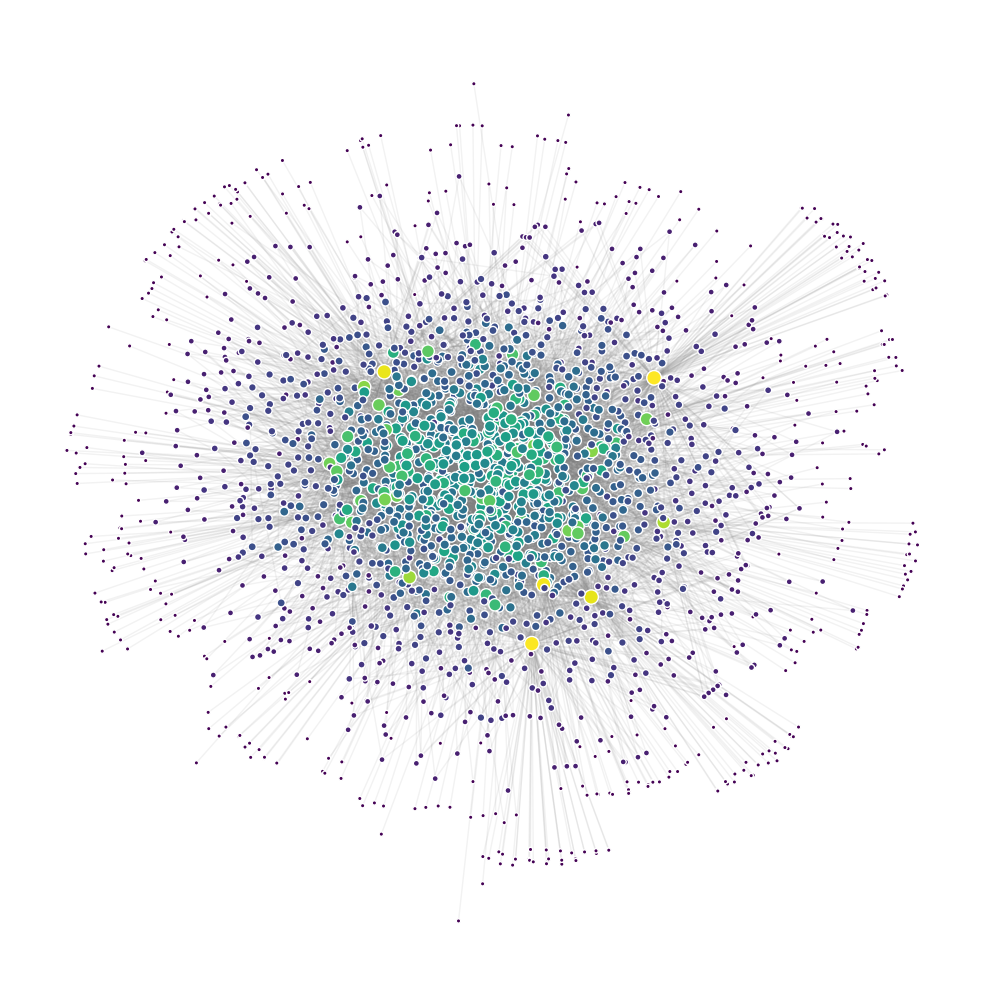

Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:01<00:00, 27.04it/s]


Refining network structure...
Refining 194 outlier nodes...


100%|██████████| 32/32 [00:00<00:00, 62.98it/s]


Refining 43 outlier nodes...


100%|██████████| 32/32 [00:00<00:00, 76.16it/s]


Refining 12 outlier nodes...


100%|██████████| 32/32 [00:00<00:00, 83.09it/s]


Refining 2 outlier nodes...


100%|██████████| 32/32 [00:00<00:00, 87.58it/s]


Calculating betweenness...
Done.
Calculating node positions...
Done.


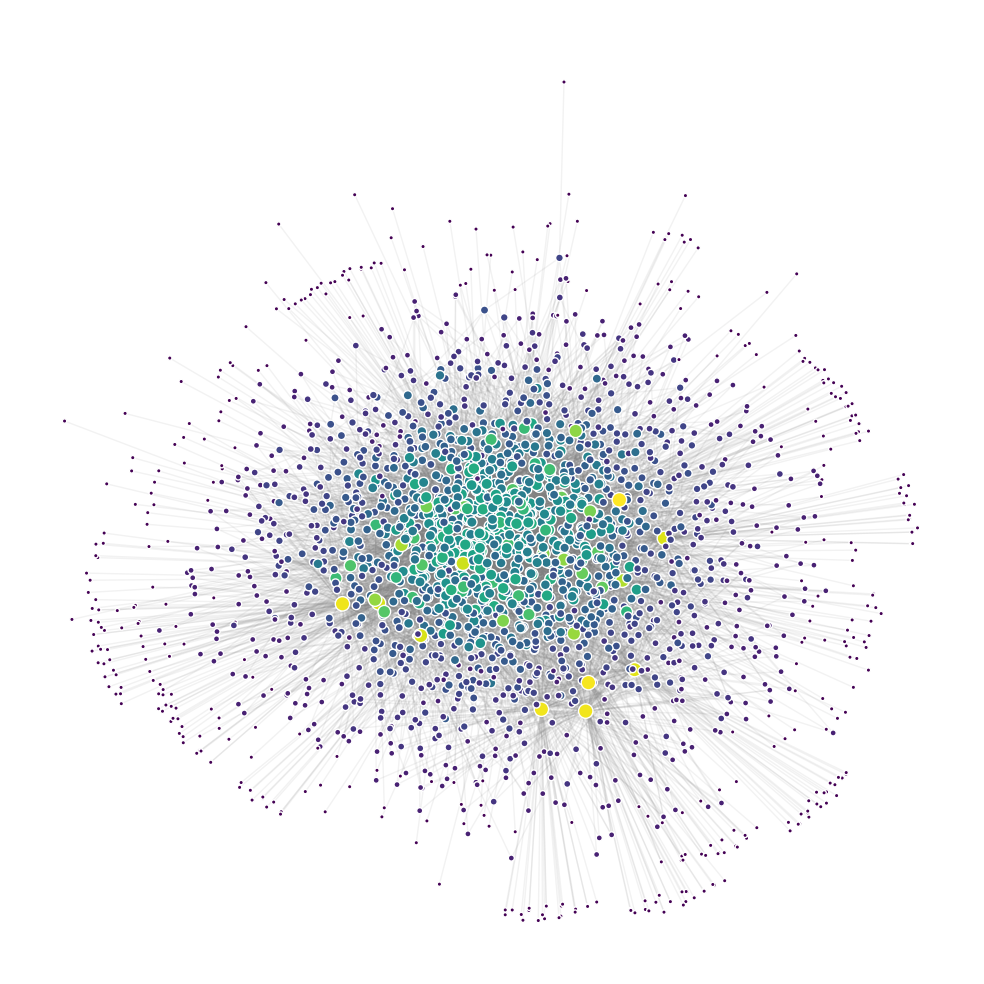

In [18]:
mfnf.generate_variants(
    plot_options = {
        'layout_func': nx.spring_layout,
        'figsize': (10,10),
        'filename':  "figures/human_proteins_network_figeys_variants_2.pdf"
    },
    filename = "variant_networks/human_proteins_network_figeys_variants_2.graphml"
)

---